# Constraint Satisfaction Problem : Graph coloring


## Create Data

We can create a planar graph with $n$ vertices by randomly placing $n$ points in 2-dimensional Euclidean space and then performing a [Delaunay triangulation](https://en.wikipedia.org/wiki/Delaunay_triangulation).

# Bài 1. Biểu diễn CSP và sinh đồ thị cần tô màu

## 1.1 Sinh đồ thị phẳng bằng phép tam giác hóa Delaunay
Đặt ngẫu nhiên $n = 10$ điểm trên lưới $100 \times 100$ (seeds `1111` để tái lập kết quả), rồi tam giác hóa Delaunay. Mỗi cạnh của tam giác là một cạnh của đồ thị. Đồ thị thu được là **đồ thị phẳng**, nên luôn tô được bằng 4 màu (định lý bốn màu).

In [ ]:
import numpy as np, time, json, os, itertools, statistics
import matplotlib.pyplot as plt
from scipy.spatial import Delaunay

os.makedirs('figs', exist_ok=True)
os.makedirs('results', exist_ok=True)
RESULTS = {}

np.random.seed(1111)
n = 10
points = np.random.randint(100, size=(n, 2))
o = np.argsort(points[:, 0])          # sắp theo toạ độ x để đánh số đỉnh từ trái sang phải
points = points[o, :]
tri = Delaunay(points)

plt.figure(figsize=(6, 5))
plt.triplot(points[:, 0], points[:, 1], tri.simplices, color="gray")
plt.plot(points[:, 0], points[:, 1], 'o', color="green", markersize=20)
for i in range(len(points)):
    plt.annotate(i, points[i, :], color='white', fontsize="large", weight='heavy',
                 horizontalalignment='center', verticalalignment='center')
plt.title("Đồ thị Delaunay, n = 10 (seed = 1111)")
plt.savefig('figs/fig1_do_thi_delaunay.png', dpi=150, bbox_inches='tight')
plt.show()
print("Toạ độ các điểm (x, y):")
print(points.tolist())

: 

## 1.2 Danh sách láng giềng (`neighbors`)
`tri.vertex_neighbor_vertices` trả về dạng CSR `(indptr, indices)`. Các láng giềng của đỉnh $k$ nằm ở `indices[indptr[k]:indptr[k+1]]`.

In [ ]:
(indptr, indices) = tri.vertex_neighbor_vertices
neighbors = [np.sort(indices[indptr[k]:indptr[k + 1]]) for k in range(len(indptr) - 1)]

for i, nb in enumerate(neighbors):
    print(f"đỉnh {i}: bậc {len(nb)}, láng giềng = {[int(x) for x in nb]}")

deg = [len(nb) for nb in neighbors]
n_edges = sum(deg) // 2
print()
print("Tổng bậc          :", sum(deg), "= 2 x số cạnh ->", 2 * n_edges)
print("Số cạnh |E|        :", n_edges)
print("Số tam giác        :", len(tri.simplices))
print("Bậc trung bình     :", sum(deg) / n)
print("Đỉnh bậc lớn nhất  :", int(np.argmax(deg)), "(bậc", max(deg), ")")
# kiểm tra quan hệ láng giềng là đối xứng
assert all(i in neighbors[j] for i in range(n) for j in neighbors[i])
# kiểm tra công thức Euler cho đồ thị phẳng liên thông: V - E + F = 2 (F gồm cả mặt ngoài)
print("Euler V - E + F    :", n - n_edges + (len(tri.simplices) + 1))
RESULTS['graph'] = {'n': n, 'edges': n_edges, 'triangles': int(len(tri.simplices)),
                    'degrees': deg, 'neighbors': [[int(x) for x in nb] for nb in neighbors]}

đỉnh 0: bậc 4, láng giềng = [1, 2, 4, 5]
đỉnh 1: bậc 3, láng giềng = [0, 5, 7]
đỉnh 2: bậc 4, láng giềng = [0, 3, 4, 9]
đỉnh 3: bậc 3, láng giềng = [2, 4, 9]
đỉnh 4: bậc 7, láng giềng = [0, 2, 3, 5, 6, 8, 9]
đỉnh 5: bậc 5, láng giềng = [0, 1, 4, 6, 7]
đỉnh 6: bậc 4, láng giềng = [4, 5, 7, 8]
đỉnh 7: bậc 4, láng giềng = [1, 5, 6, 8]
đỉnh 8: bậc 4, láng giềng = [4, 6, 7, 9]
đỉnh 9: bậc 4, láng giềng = [2, 3, 4, 8]

Tổng bậc          : 42 = 2 x số cạnh -> 42
Số cạnh |E|        : 21
Số tam giác        : 12
Bậc trung bình     : 4.2
Đỉnh bậc lớn nhất  : 4 (bậc 7 )
Euler V - E + F    : 2


## 1.3 Mô hình hóa CSP: $X$, $D$, $C$
CSP được lưu thành một `dict` gồm ba thành phần: `variables`, `domains`, `constraints`.

* **Biến** $X = \{0, 1, \dots, n-1\}$ (ở code là chuỗi `'0'`…`'9'`): mỗi đỉnh là một biến.
* **Miền giá trị** $D_i = \{\text{red, blue, green, orange}\}$ (4 màu) hoặc $\{\text{red, blue, green}\}$ (3 màu).
* **Ràng buộc** $C_{ij}$: $\text{color}(i) \neq \text{color}(j)$ với mọi cạnh $(i, j)$ của đồ thị.

**Vì sao chỉ tạo ràng buộc cho $i < j$?** Quan hệ láng giềng đối xứng: nếu $j \in N(i)$ thì $i \in N(j)$. Ràng buộc $\text{color}(i) \neq \text{color}(j)$ cũng đối xứng, nên $C_{ij}$ và $C_{ji}$ là **cùng một ràng buộc**. Lấy điều kiện $i < j$ để mỗi cạnh chỉ xuất hiện đúng một lần, tránh lặp ràng buộc (mỗi lần kiểm tra thừa là một phép so sánh thừa trong `consistent()`).

In [ ]:
variables = [str(v) for v in range(n)]

domain4 = ['red', 'blue', 'green', 'orange']
domain3 = ['red', 'blue', 'green']
domains4 = {v: list(domain4) for v in variables}
domains3 = {v: list(domain3) for v in variables}

# ràng buộc nhị phân "khác nhau": mỗi cạnh (i, j) với i < j chỉ xuất hiện một lần
constraints = [(str(i), str(int(j))) for i in range(n) for j in neighbors[i] if i < j]
# nếu không có điều kiện i < j thì mỗi cạnh bị lặp hai lần:
constraints_full = [(str(i), str(int(j))) for i in range(n) for j in neighbors[i]]

csp4 = {'variables': variables, 'domains': domains4, 'constraints': constraints}
csp3 = {'variables': variables, 'domains': domains3, 'constraints': constraints}

print("Số biến             :", len(variables))
print("Kích thước miền (4) :", len(domain4), " (3):", len(domain3))
print("Số ràng buộc (i<j)  :", len(constraints))
print("Số ràng buộc nếu bỏ i<j:", len(constraints_full), "(gấp đôi, mỗi cạnh lặp 2 lần)")
print("Danh sách ràng buộc :", constraints)
print("Các khoá của csp    :", list(csp4.keys()))

Số biến             : 10
Kích thước miền (4) : 4  (3): 3
Số ràng buộc (i<j)  : 21
Số ràng buộc nếu bỏ i<j: 42 (gấp đôi, mỗi cạnh lặp 2 lần)
Danh sách ràng buộc : [('0', '1'), ('0', '2'), ('0', '4'), ('0', '5'), ('1', '5'), ('1', '7'), ('2', '3'), ('2', '4'), ('2', '9'), ('3', '4'), ('3', '9'), ('4', '5'), ('4', '6'), ('4', '8'), ('4', '9'), ('5', '6'), ('5', '7'), ('6', '7'), ('6', '8'), ('7', '8'), ('8', '9')]
Các khoá của csp    : ['variables', 'domains', 'constraints']


## 1.4 Khảo sát miền 4 màu và 3 màu; phép gán đầy đủ và phép gán hợp lệ

* **Phép gán đầy đủ (complete):** mọi biến đều có giá trị. Không xét đến ràng buộc.
* **Phép gán hợp lệ / nhất quán (consistent):** không ràng buộc nào bị vi phạm trong số các biến đã được gán. Phép gán từng phần cũng có thể hợp lệ.
* **Nghiệm của CSP:** phép gán vừa **đầy đủ** vừa **hợp lệ** (và mọi giá trị thuộc miền của biến).

Có tất cả $4^{10} = 1\,048\,576$ phép gán đầy đủ với 4 màu, nhưng chỉ một phần rất nhỏ trong số đó là nghiệm. Ta đếm chính xác bằng cách liệt kê toàn bộ các cách tô hợp lệ.

In [ ]:
adj = {v: set() for v in variables}
for x, y in constraints:
    adj[x].add(y); adj[y].add(x)

def count_colorings(k):
    """Đếm số cách tô hợp lệ bằng k màu (liệt kê có cắt nhánh)."""
    cnt = 0
    a = {}
    def rec(idx):
        nonlocal cnt
        if idx == n:
            cnt += 1; return
        v = variables[idx]
        for c in range(k):
            if all(a.get(u) != c for u in adj[v]):
                a[v] = c; rec(idx + 1); del a[v]
    rec(0)
    return cnt

valid4 = count_colorings(4)
valid3 = count_colorings(3)
print(f"4 màu: số phép gán đầy đủ = {4**n:,}; số nghiệm (hợp lệ) = {valid4:,}; tỉ lệ = {valid4 / 4**n:.4%}")
print(f"3 màu: số phép gán đầy đủ = {3**n:,}; số nghiệm (hợp lệ) = {valid3:,}")
RESULTS['solutions'] = {'complete4': 4**n, 'valid4': valid4, 'complete3': 3**n, 'valid3': valid3}

4 màu: số phép gán đầy đủ = 1,048,576; số nghiệm (hợp lệ) = 480; tỉ lệ = 0.0458%
3 màu: số phép gán đầy đủ = 59,049; số nghiệm (hợp lệ) = 0


### Vì sao đồ thị này **không** tô được bằng 3 màu?
Đỉnh 4 có bậc 7. Các láng giềng của nó là $\{0, 2, 3, 5, 6, 8, 9\}$. Nếu các láng giềng này tạo thành một chu trình nối tiếp nhau thì ta có một "bánh xe" (wheel) $W_7$: đỉnh 4 là tâm, 7 đỉnh kia là vành. Chu trình vành có độ dài **lẻ** nên cần ≥ 3 màu; tâm kề với cả vành nên cần màu thứ 4. Ta kiểm tra bằng code.

In [ ]:
hub = 4
rim = [0, 2, 3, 9, 8, 6, 5]                      # thứ tự đi vòng quanh đỉnh 4
edge_set = {frozenset((int(a), int(b))) for a, b in constraints}
rim_edges = [(rim[i], rim[(i + 1) % len(rim)]) for i in range(len(rim))]
print("Láng giềng của đỉnh 4       :", [int(x) for x in neighbors[hub]])
print("Mọi đỉnh vành đều kề đỉnh 4 :", all(frozenset((hub, r)) in edge_set for r in rim))
print("Các cạnh của chu trình vành :", rim_edges)
print("Mọi cạnh vành đều có thật   :", all(frozenset(e) in edge_set for e in rim_edges))
print("Độ dài chu trình vành       :", len(rim), "(lẻ)")

Láng giềng của đỉnh 4       : [0, 2, 3, 5, 6, 8, 9]
Mọi đỉnh vành đều kề đỉnh 4 : True
Các cạnh của chu trình vành : [(0, 2), (2, 3), (3, 9), (9, 8), (8, 6), (6, 5), (5, 0)]
Mọi cạnh vành đều có thật   : True
Độ dài chu trình vành       : 7 (lẻ)


**Kết luận Bài 1.** Với 4 màu, CSP có nghiệm (và nhiều nghiệm, xem số liệu ở trên). Với 3 màu, CSP **vô nghiệm** vì đồ thị chứa bánh xe $W_7$ (vành lẻ) nên cần ít nhất 4 màu. Cùng một thuật toán đúng nhưng thất bại khi miền chỉ có 3 màu — đó là thất bại do **bài toán không có nghiệm**, không phải do thuật toán sai.

# Bài 2. Kiểm tra tính đầy đủ và nhất quán

`assignment` là một `dict`: biến đã gán có một khoá tương ứng, `{}` là phép gán rỗng.

In [ ]:
def complete(assignment, csp):
    """Đầy đủ: mọi biến của CSP đều đã được gán."""
    return all(v in assignment.keys() for v in csp['variables'])

def consistent(assignment, csp):
    """Nhất quán: không có ràng buộc nào bị vi phạm giữa các biến ĐÃ gán."""
    for x, y in csp['constraints']:
        if x in assignment and y in assignment:
            if assignment[x] == assignment[y]:
                return False
    return True

# hàm phụ (không có trong notebook gốc): kiểm tra giá trị nằm trong miền, và nghiệm = đầy đủ + nhất quán + đúng miền
def in_domain(assignment, csp):
    return all(val in csp['domains'][var] for var, val in assignment.items())

def is_solution(assignment, csp):
    return complete(assignment, csp) and consistent(assignment, csp) and in_domain(assignment, csp)

print("Các ví dụ gốc trong notebook:")
print("complete({}, csp) =", complete({}, csp4))
print("consistent({}, csp) =", consistent({}, csp4))
print("consistent({'0':'red','1':'red','2':'blue'}, csp) =",
      consistent({'0': 'red', '1': 'red', '2': 'blue'}, csp4), " (0 và 1 là hai đỉnh kề nhau, cùng đỏ)")

Các ví dụ gốc trong notebook:
complete({}, csp) = False
consistent({}, csp) = True
consistent({'0':'red','1':'red','2':'blue'}, csp) = False  (0 và 1 là hai đỉnh kề nhau, cùng đỏ)


## Các ca kiểm thử (ghi rõ kết quả mong đợi)
Kết quả mong đợi được suy ra **bằng tay từ đồ thị** (danh sách cạnh ở Bài 1), sau đó so với kết quả của hàm bằng `assert`.

In [ ]:
good = {'0': 'red', '1': 'blue', '2': 'blue', '3': 'red', '4': 'green',
        '5': 'orange', '6': 'red', '7': 'green', '8': 'blue', '9': 'orange'}
all_red = {v: 'red' for v in variables}

tests = [
    # (tên, phép gán, complete mong đợi, consistent mong đợi, lý do)
    ("T1 rỗng",                      {},                                         False, True,  "chưa gán biến nào; không có ràng buộc nào bị vi phạm"),
    ("T2 từng phần, hợp lệ",         {'0': 'red', '1': 'blue', '2': 'green'},    False, True,  "(0,1) và (0,2) là cạnh, màu khác nhau; (1,2) không phải cạnh"),
    ("T3 từng phần, 2 đỉnh kề cùng màu", {'0': 'red', '1': 'red'},               False, False, "(0,1) là cạnh nhưng cùng đỏ"),
    ("T4 đầy đủ, hợp lệ (nghiệm)",   good,                                       True,  True,  "đủ 10 biến, 21 cạnh đều có hai đầu khác màu"),
    ("T5 đầy đủ, tất cả đỏ",         all_red,                                    True,  False, "đủ 10 biến nhưng mọi cạnh đều vi phạm"),
    ("T6 đầy đủ, sai 2 cạnh",        {**good, '8': 'green'},                     True,  False, "đổi đỉnh 8 thành green: (4,8) và (7,8) đều vi phạm vì đỉnh 4 và 7 cũng green"),
    ("T7 giá trị ngoài miền",        {'0': 'purple'},                            False, True,  "consistent() không kiểm tra miền -> vẫn True"),
]

print(f"{'Ca kiểm thử':36s} {'complete':>9s} {'(mong đợi)':>11s} {'consistent':>11s} {'(mong đợi)':>11s}  nghiệm?")
for name, a, exp_c, exp_k, why in tests:
    c, k = complete(a, csp4), consistent(a, csp4)
    assert c == exp_c and k == exp_k, name
    print(f"{name:36s} {str(c):>9s} {str(exp_c):>11s} {str(k):>11s} {str(exp_k):>11s}  {is_solution(a, csp4)}")
print("\nTất cả ca kiểm thử đạt (assert không báo lỗi).")
RESULTS['tests'] = [{'name': t[0], 'complete': complete(t[1], csp4), 'consistent': consistent(t[1], csp4),
                     'solution': is_solution(t[1], csp4)} for t in tests]

Ca kiểm thử                           complete  (mong đợi)  consistent  (mong đợi)  nghiệm?
T1 rỗng                                  False       False        True        True  False
T2 từng phần, hợp lệ                     False       False        True        True  False
T3 từng phần, 2 đỉnh kề cùng màu         False       False       False       False  False
T4 đầy đủ, hợp lệ (nghiệm)                True        True        True        True  True
T5 đầy đủ, tất cả đỏ                      True        True       False       False  False
T6 đầy đủ, sai 2 cạnh                     True        True       False       False  False
T7 giá trị ngoài miền                    False       False        True        True  False

Tất cả ca kiểm thử đạt (assert không báo lỗi).


## Nhận xét và dạng lưu trữ

* `complete()` chỉ trả lời "đã gán hết biến chưa?"; `consistent()` chỉ trả lời "có ràng buộc nào bị vi phạm chưa?". Hai hàm độc lập nhau: T3 (không đầy đủ, không nhất quán), T2 (không đầy đủ, nhất quán), T5 (đầy đủ, không nhất quán), T4 (cả hai). Vì vậy **`complete()` không đồng nghĩa `consistent()`**, và ngược lại.
* **Nghiệm CSP = đầy đủ ∧ nhất quán** (∧ mọi giá trị thuộc miền). Một phép gán đầy đủ chưa chắc là nghiệm (T5, T6); một phép gán từng phần nhất quán chưa phải nghiệm (T2).
* Phép gán rỗng luôn nhất quán (vacuous truth), do đó `consistent()` là điều kiện **cần** để cắt nhánh trong backtracking, nhưng không đủ để kết luận đã xong.
* `consistent()` ở bản gốc không kiểm tra giá trị có thuộc miền hay không (T7). Với backtracking điều này không gây lỗi vì chỉ duyệt các giá trị trong `domains`, nhưng khi nhận phép gán từ bên ngoài nên dùng `is_solution()`.

In [ ]:
print("Dạng lưu trữ csp:")
for k, v in csp4.items():
    print(f"  csp['{k}']: {type(v).__name__}, độ dài {len(v)}")
print("  variables  :", csp4['variables'])
print("  domains['0']:", csp4['domains']['0'])
print("  constraints[:5]:", csp4['constraints'][:5], "...")

Dạng lưu trữ csp:
  csp['variables']: list, độ dài 10
  csp['domains']: dict, độ dài 10
  csp['constraints']: list, độ dài 21
  variables  : ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']
  domains['0']: ['red', 'blue', 'green', 'orange']
  constraints[:5]: [('0', '1'), ('0', '2'), ('0', '4'), ('0', '5'), ('1', '5')] ...


# Bài 3. Backtracking Search và thứ tự chọn biến

## 3.1 Backtracking gốc (chọn biến chưa gán đầu tiên, thử giá trị theo thứ tự miền)
Mã dưới đây giữ nguyên cấu trúc bản gốc (biến toàn cục `COUNT` đếm số nút được kiểm tra, mỗi lần gọi `backtrack()` tính là một nút). Ta thêm biến `ATTEMPTS` để đếm số lần thử gán một giá trị cho một biến (số "variable assignments attempted" mà đề Assignment nhắc đến).

Kết quả: {'0': 'red', '1': 'blue', '2': 'blue', '3': 'red', '4': 'green', '5': 'orange', '6': 'red', '7': 'green', '8': 'blue', '9': 'orange'}
COUNT = 11, ATTEMPTS = 23, thời gian 1 lần chạy = 0.102 ms
Là nghiệm hợp lệ: True


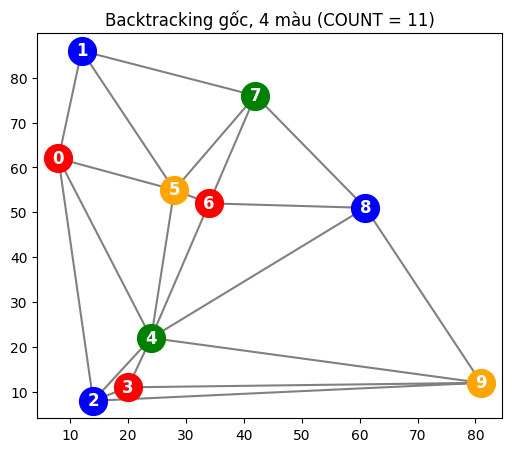

In [ ]:
COUNT = 0       # số nút (số lần gọi backtrack)
ATTEMPTS = 0    # số lần thử gán giá trị cho biến

def select_unassigned_var(assignment, csp):
    """Bản gốc: chọn biến chưa gán đầu tiên theo thứ tự khai báo."""
    if complete(assignment, csp): return None
    for v in csp['variables']:
        if v not in assignment:
            return v

def order_domain(assignment, var, csp):
    """Bản gốc: giá trị theo đúng thứ tự trong miền."""
    return list(csp['domains'][var])

def backtrack_search(csp, select=select_unassigned_var, order=order_domain):
    global COUNT, ATTEMPTS
    COUNT = 0; ATTEMPTS = 0
    return backtrack({}, csp, select, order)

def backtrack(assignment, csp, select, order):
    global COUNT, ATTEMPTS
    COUNT += 1
    if complete(assignment, csp):
        return dict(assignment)
    var = select(assignment, csp)
    for val in order(assignment, var, csp):
        assignment[var] = val
        ATTEMPTS += 1
        if consistent(assignment, csp):
            result = backtrack(assignment, csp, select, order)
            if result is not None:
                return result
        del assignment[var]
    return None            # thất bại -> quay lui

def plot_coloring(res, title, fname=None):
    """Vẽ tô màu. Dùng res[str(i)] (không dùng thứ tự của res.values()) để đúng cả khi chọn biến theo MRV."""
    plt.figure(figsize=(6, 5))
    plt.triplot(points[:, 0], points[:, 1], tri.simplices, color="gray")
    for i in range(len(points)):
        plt.plot(points[i, 0], points[i, 1], 'o', color=res[str(i)], markersize=20)
        plt.annotate(i, points[i, :], color='white', fontsize="large", weight='heavy',
                     horizontalalignment='center', verticalalignment='center')
    plt.title(title)
    if fname: plt.savefig(fname, dpi=150, bbox_inches='tight')
    plt.show()

# ---- chạy 4 màu ----
t0 = time.perf_counter()
res_orig4 = backtrack_search(csp4)
t_once = time.perf_counter() - t0
print("Kết quả:", dict(sorted(res_orig4.items(), key=lambda kv: int(kv[0]))))
print(f"COUNT = {COUNT}, ATTEMPTS = {ATTEMPTS}, thời gian 1 lần chạy = {t_once*1000:.3f} ms")
print("Là nghiệm hợp lệ:", is_solution(res_orig4, csp4))
plot_coloring(res_orig4, "Backtracking gốc, 4 màu (COUNT = %d)" % COUNT, 'figs/fig2_backtracking_goc_4mau.png')

**Nhận xét.** `COUNT = 11 = n + 1`: 1 nút gốc (phép gán rỗng) + 10 nút cho 10 biến, tức là thuật toán **không phải quay lui lần nào** ở nút cấp biến (có 13 lần thử gán thừa, tất cả bị `consistent()` loại ngay tại chỗ, xem `ATTEMPTS`). Với n = 10 và 4 màu bài toán quá dễ nên ba chiến lược sẽ không phân biệt rõ; ta sẽ cần đồ thị lớn hơn và trường hợp 3 màu (vô nghiệm) để thấy khác biệt.

Lưu ý khi vẽ: đoạn vẽ trong bản gốc dùng `list(res.values())[i]`, chỉ đúng khi thứ tự chèn vào `dict` trùng thứ tự đỉnh. Khi chọn biến bằng MRV thì thứ tự chèn thay đổi (xem phần sau), nên hàm `plot_coloring` ở trên dùng `res[str(i)]`.

In [ ]:
# ---- chạy 3 màu: vô nghiệm ----
res_orig3 = backtrack_search(csp3)
print("Kết quả 3 màu:", res_orig3)
print(f"COUNT = {COUNT}, ATTEMPTS = {ATTEMPTS}")

Kết quả 3 màu: None
COUNT = 70, ATTEMPTS = 210


Với 3 màu, `backtrack_search` trả về `None` sau khi **duyệt hết** cây tìm kiếm (COUNT = 70). Vì thuật toán backtracking là đầy đủ trên CSP hữu hạn, việc duyệt hết mà không có nghiệm chính là **chứng minh vô nghiệm** (khớp với lập luận bánh xe $W_7$ ở Bài 1). Đây khác với trường hợp dừng vì hết thời gian/giới hạn tính toán (khi đó chưa kết luận được gì).

## 3.2 MRV (Minimum Remaining Values) trên miền còn hợp lệ
Ở mỗi bước, với mỗi biến chưa gán ta tính **các giá trị còn hợp lệ** = các màu trong miền chưa bị láng giềng *đã gán* sử dụng. MRV chọn biến có ít giá trị hợp lệ nhất ("fail-first": nếu một biến sắp hết lựa chọn thì nên gán nó sớm để phát hiện ngõ cụt sớm). Khi hòa, dùng **degree heuristic**: ưu tiên biến có nhiều láng giềng chưa gán nhất.

In [ ]:
def legal_values(assignment, var, csp):
    """Các giá trị trong miền của var không trùng màu láng giềng đã gán."""
    used = {assignment[u] for u in adj[var] if u in assignment}
    return [c for c in csp['domains'][var] if c not in used]

def select_unassigned_var_mrv(assignment, csp):
    if complete(assignment, csp): return None
    best, best_key = None, None
    for v in csp['variables']:
        if v in assignment: continue
        free_nb = sum(1 for u in adj[v] if u not in assignment)
        key = (len(legal_values(assignment, v, csp)), -free_nb)   # ít giá trị nhất, rồi bậc (chưa gán) lớn nhất
        if best_key is None or key < best_key:
            best, best_key = v, key
    return best

# minh hoạ trên phép gán từng phần {'4': 'red'}
a = {'4': 'red'}
print("Phép gán từng phần:", a)
print("Số giá trị hợp lệ còn lại của từng biến chưa gán:")
for v in variables:
    if v not in a:
        print(f"  biến {v}: {legal_values(a, v, csp4)}  -> {len(legal_values(a, v, csp4))} giá trị")
print("Bản gốc chọn      :", select_unassigned_var(a, csp4))
print("MRV chọn          :", select_unassigned_var_mrv(a, csp4))

Phép gán từng phần: {'4': 'red'}
Số giá trị hợp lệ còn lại của từng biến chưa gán:
  biến 0: ['blue', 'green', 'orange']  -> 3 giá trị
  biến 1: ['red', 'blue', 'green', 'orange']  -> 4 giá trị
  biến 2: ['blue', 'green', 'orange']  -> 3 giá trị
  biến 3: ['blue', 'green', 'orange']  -> 3 giá trị
  biến 5: ['blue', 'green', 'orange']  -> 3 giá trị
  biến 6: ['blue', 'green', 'orange']  -> 3 giá trị
  biến 7: ['red', 'blue', 'green', 'orange']  -> 4 giá trị
  biến 8: ['blue', 'green', 'orange']  -> 3 giá trị
  biến 9: ['blue', 'green', 'orange']  -> 3 giá trị
Bản gốc chọn      : 0
MRV chọn          : 5


Bản gốc chọn biến `'0'` chỉ vì nó đứng đầu danh sách. MRV chọn biến `5`: các biến kề đỉnh 4 (0, 2, 3, 5, 6, 8, 9) chỉ còn 3 màu, còn biến 1 và 7 (không kề đỉnh 4) vẫn còn 4 màu; trong số các biến còn 3 màu, biến 5 có nhiều láng giềng chưa gán nhất nên thắng ở bước hòa.

## 3.3 Least Constraining Value (LCV)
Với biến đã chọn, LCV sắp xếp các giá trị hợp lệ theo **số lựa chọn mà nó làm mất đi ở các láng giềng chưa gán**, từ ít đến nhiều: giá trị nào "ít ảnh hưởng" nhất thì thử trước, để chừa nhiều khả năng cho các biến sau.

In [ ]:
def order_domain_lcv(assignment, var, csp):
    vals = legal_values(assignment, var, csp)
    def ruled_out(c):
        # số láng giềng chưa gán đang còn dùng được màu c (gán c cho var sẽ làm mất màu này của họ)
        return sum(1 for u in adj[var] if u not in assignment and c in legal_values(assignment, u, csp))
    return sorted(vals, key=ruled_out)       # sort ổn định: hòa thì giữ thứ tự miền

a = {'4': 'red', '5': 'blue', '0': 'green'}
print("Phép gán từng phần:", a, "; xét biến '3' (láng giềng chưa gán: 2 và 9)")
for c in legal_values(a, '3', csp4):
    r = sum(1 for u in adj['3'] if u not in a and c in legal_values(a, u, csp4))
    print(f"  màu {c:7s}: làm mất lựa chọn của {r} láng giềng chưa gán")
print("Thứ tự mặc định :", order_domain(a, '3', csp4))
print("Thứ tự LCV      :", order_domain_lcv(a, '3', csp4))

Phép gán từng phần: {'4': 'red', '5': 'blue', '0': 'green'} ; xét biến '3' (láng giềng chưa gán: 2 và 9)
  màu blue   : làm mất lựa chọn của 2 láng giềng chưa gán
  màu green  : làm mất lựa chọn của 1 láng giềng chưa gán
  màu orange : làm mất lựa chọn của 2 láng giềng chưa gán
Thứ tự mặc định : ['red', 'blue', 'green', 'orange']
Thứ tự LCV      : ['green', 'blue', 'orange']


## 3.4 So sánh 4 biến thể trên cùng một đồ thị (n = 10, seed = 1111)
Bốn biến thể: gốc; MRV; LCV; MRV + LCV. Thời gian là trung bình của 300 lần chạy (một lần chạy chỉ cỡ vài chục micro-giây nên đo một lần sẽ nhiễu). Mọi nghiệm tìm được đều được kiểm tra lại bằng `is_solution`.

--- 4 màu ---
Biến thể                                    COUNT  ATTEMPTS   ms/lần  kết quả
Gốc (biến đầu tiên, giá trị theo miền)         11        23    0.045  nghiệm hợp lệ
MRV                                            11        25    0.101  nghiệm hợp lệ
LCV                                            11        10    0.083  nghiệm hợp lệ
MRV + LCV                                      11        10    0.188  nghiệm hợp lệ
--- 3 màu ---
Biến thể                                    COUNT  ATTEMPTS   ms/lần  kết quả


Gốc (biến đầu tiên, giá trị theo miền)         70       210    0.342  vô nghiệm (duyệt hết)
MRV                                            34       102    0.401  vô nghiệm (duyệt hết)


LCV                                            70        69    0.445  vô nghiệm (duyệt hết)
MRV + LCV                                      34        33    0.439  vô nghiệm (duyệt hết)

Thứ tự gán của MRV + LCV (thứ tự khoá trong dict): ['4', '5', '0', '2', '6', '7', '1', '9', '3', '8']


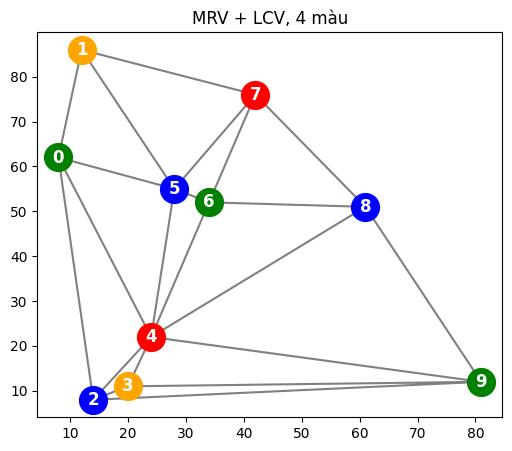

In [ ]:
variants = {
    'Gốc (biến đầu tiên, giá trị theo miền)': (select_unassigned_var,     order_domain),
    'MRV':                                    (select_unassigned_var_mrv, order_domain),
    'LCV':                                    (select_unassigned_var,     order_domain_lcv),
    'MRV + LCV':                              (select_unassigned_var_mrv, order_domain_lcv),
}

def run_variant(csp, sel, ordr, reps=300):
    res = backtrack_search(csp, sel, ordr)
    cnt, att = COUNT, ATTEMPTS
    t0 = time.perf_counter()
    for _ in range(reps): backtrack_search(csp, sel, ordr)
    ms = (time.perf_counter() - t0) / reps * 1000
    ok = None if res is None else is_solution(res, csp)
    return res, cnt, att, ms, ok

table_n10 = []
for k, csp in ((4, csp4), (3, csp3)):
    print(f"--- {k} màu ---")
    print(f"{'Biến thể':42s} {'COUNT':>6s} {'ATTEMPTS':>9s} {'ms/lần':>8s}  kết quả")
    for name, (sel, ordr) in variants.items():
        res, cnt, att, ms, ok = run_variant(csp, sel, ordr)
        status = "nghiệm hợp lệ" if ok else "vô nghiệm (duyệt hết)"
        print(f"{name:42s} {cnt:6d} {att:9d} {ms:8.3f}  {status}")
        table_n10.append({'colors': k, 'variant': name, 'count': cnt, 'attempts': att, 'ms': ms, 'solved': bool(ok)})
        if k == 4 and name == 'MRV + LCV': res_mrv_lcv = res
RESULTS['table_n10'] = table_n10
print("\nThứ tự gán của MRV + LCV (thứ tự khoá trong dict):", list(res_mrv_lcv.keys()))
plot_coloring(res_mrv_lcv, "MRV + LCV, 4 màu", 'figs/fig3_mrv_lcv_4mau.png')

**Nhận xét (n = 10).**

* Với **4 màu**, cả bốn biến thể đều có `COUNT = 11` (không quay lui nút nào). Khác biệt chỉ nằm ở `ATTEMPTS`: bản gốc thử gán 23 lần, LCV chỉ 10 lần = đúng 10 biến, mỗi biến thử đúng một màu hợp lệ. Hai biến thể có LCV (LCV, MRV + LCV) chỉ thử các giá trị còn hợp lệ nên không có lần thử nào bị `consistent()` loại; MRV đứng một mình vẫn thử theo thứ tự miền nên còn 25 lần thử. Thứ tự gán của MRV khác thứ tự `0, 1, 2, …` (đỉnh bậc 7 là đỉnh 4 được gán đầu tiên), do đó `list(res.values())[i]` sẽ tô sai màu nếu dùng cách vẽ cũ.
* Với **3 màu** (vô nghiệm), MRV giảm `COUNT` từ 70 xuống 34 (≈ 51 %) vì phát hiện ngõ cụt sớm hơn. LCV **không giúp** (COUNT vẫn 70): khi bài toán vô nghiệm thuật toán bắt buộc phải duyệt hết mọi giá trị hợp lệ của mọi nhánh, nên thứ tự giá trị không đổi kích thước cây. LCV chỉ có tác dụng khi tồn tại nghiệm (giúp tìm thấy nghiệm sớm hơn).
* Thời gian: MRV và LCV phải tính lại tập giá trị hợp lệ ở mỗi nút nên **mỗi nút tốn kém hơn**; với đồ thị nhỏ chi phí này lấn át lợi ích giảm nút nên thời gian không giảm, thậm chí tăng nhẹ.

## 3.5 Khảo sát trên nhiều đồ thị ngẫu nhiên lớn hơn
Để thấy tác động thật của MRV/LCV, ta sinh 20 đồ thị Delaunay ngẫu nhiên (seed 0…19) cho mỗi $n$ và đo trung bình `COUNT`, thời gian và số lần giải được (4 màu: $n$ = 10, 20, 30, 40, 60; 3 màu: $n$ = 8, 10, 12, 14, 16). Có giới hạn an toàn 200 000 nút/lần để tránh chạy vô hạn (thực tế không có lần nào chạm giới hạn).

In [ ]:
def make_instance(nn, seed, k):
    """Sinh đồ thị Delaunay ngẫu nhiên n đỉnh (tách khỏi biến toàn cục để dùng lại)."""
    rng = np.random.RandomState(seed)
    pts = rng.randint(100, size=(nn, 2)); pts = pts[np.argsort(pts[:, 0]), :]
    t = Delaunay(pts)
    ip, ind = t.vertex_neighbor_vertices
    nbs = [np.sort(ind[ip[i]:ip[i + 1]]) for i in range(len(ip) - 1)]
    vs = [str(v) for v in range(nn)]
    cons = [(str(i), str(int(j))) for i in range(nn) for j in nbs[i] if i < j]
    dom = ['red', 'blue', 'green', 'orange'][:k]
    return {'variables': vs, 'domains': {v: list(dom) for v in vs}, 'constraints': cons}

LIMIT = 200000
class LimitReached(Exception): pass

def backtrack_limited(csp, sel, ordr):
    """Giống backtrack_search nhưng ngắt khi COUNT vượt LIMIT; trả về (kết quả, COUNT, ATTEMPTS)."""
    global adj
    adj = {v: set() for v in csp['variables']}
    for x, y in csp['constraints']:
        adj[x].add(y); adj[y].add(x)
    try:
        r = backtrack_search_limit(csp, sel, ordr)
    except LimitReached:
        r = 'LIMIT'
    return r, COUNT, ATTEMPTS

def backtrack_search_limit(csp, sel, ordr):
    global COUNT, ATTEMPTS
    COUNT = 0; ATTEMPTS = 0
    def rec(a):
        global COUNT, ATTEMPTS
        COUNT += 1
        if COUNT > LIMIT: raise LimitReached
        if complete(a, csp): return dict(a)
        var = sel(a, csp)
        for val in ordr(a, var, csp):
            a[var] = val; ATTEMPTS += 1
            if consistent(a, csp):
                r = rec(a)
                if r is not None: return r
            del a[var]
        return None
    return rec({})

SEEDS = range(20)
scaling = []
for k, ns in ((4, [10, 20, 30, 40, 60]), (3, [8, 10, 12, 14, 16])):
    for nn in ns:
        agg = {name: {'count': [], 'att': [], 'ms': [], 'solved': 0, 'unsat': 0, 'limit': 0} for name in variants}
        edges = []
        for seed in SEEDS:
            inst = make_instance(nn, seed, k); edges.append(len(inst['constraints']))
            for name, (sel, ordr) in variants.items():
                t0 = time.perf_counter()
                r, cnt, att = backtrack_limited(inst, sel, ordr)
                dt = (time.perf_counter() - t0) * 1000
                g = agg[name]; g['count'].append(cnt); g['att'].append(att); g['ms'].append(dt)
                if r == 'LIMIT': g['limit'] += 1
                elif r is None: g['unsat'] += 1
                else:
                    assert is_solution(r, inst); g['solved'] += 1
        for name in variants:
            g = agg[name]
            scaling.append({'colors': k, 'n': nn, 'avg_edges': statistics.mean(edges), 'variant': name,
                            'count_mean': statistics.mean(g['count']), 'count_max': max(g['count']),
                            'att_mean': statistics.mean(g['att']), 'ms_mean': statistics.mean(g['ms']),
                            'solved': g['solved'], 'unsat': g['unsat'], 'limit': g['limit']})
RESULTS['scaling'] = scaling

import pandas as pd
df = pd.DataFrame(scaling)
for k in (4, 3):
    print(f"\n=== {k} màu: COUNT trung bình (20 đồ thị mỗi n) ===")
    piv = df[df.colors == k].pivot_table(index=['n', 'avg_edges'], columns='variant', values='count_mean')[list(variants)]
    print(piv.round(1).to_string())
    print(f"--- {k} màu: số đồ thị giải được / vô nghiệm (theo từng n) ---")
    s = df[(df.colors == k) & (df.variant == 'MRV')][['n', 'solved', 'unsat', 'limit']]
    print(s.to_string(index=False))


=== 4 màu: COUNT trung bình (20 đồ thị mỗi n) ===
variant       Gốc (biến đầu tiên, giá trị theo miền)   MRV    LCV  MRV + LCV
n  avg_edges                                                                
10 21.10                                        12.6  11.0   12.4       11.0
20 49.35                                        24.2  22.0   23.8       23.6
30 78.25                                        56.9  35.1   55.0       33.4
40 107.10                                      109.9  43.8  127.6       46.2
60 166.10                                      828.8  71.8  913.4       87.0
--- 4 màu: số đồ thị giải được / vô nghiệm (theo từng n) ---
 n  solved  unsat  limit
10      20      0      0
20      20      0      0
30      20      0      0
40      20      0      0
60      20      0      0

=== 3 màu: COUNT trung bình (20 đồ thị mỗi n) ===
variant       Gốc (biến đầu tiên, giá trị theo miền)   MRV   LCV  MRV + LCV
n  avg_edges                                                            


=== 4 màu: ATTEMPTS trung bình (số lần thử gán) ===
variant  Gốc (biến đầu tiên, giá trị theo miền)    MRV    LCV  MRV + LCV
n                                                                       
10                                         29.1   24.4   11.4       10.0
20                                         58.6   52.9   22.8       22.6
30                                        173.5   90.4   54.0       32.4
40                                        368.8  109.2  126.6       45.2
60                                       3213.0  192.4  912.4       86.0

=== 3 màu: ATTEMPTS trung bình (số lần thử gán) ===
variant  Gốc (biến đầu tiên, giá trị theo miền)    MRV   LCV  MRV + LCV
n                                                                      
8                                         105.4   65.8  34.6       21.4
10                                        153.3   85.8  50.1       27.6
12                                        198.3  102.0  65.1       33.0
14                     

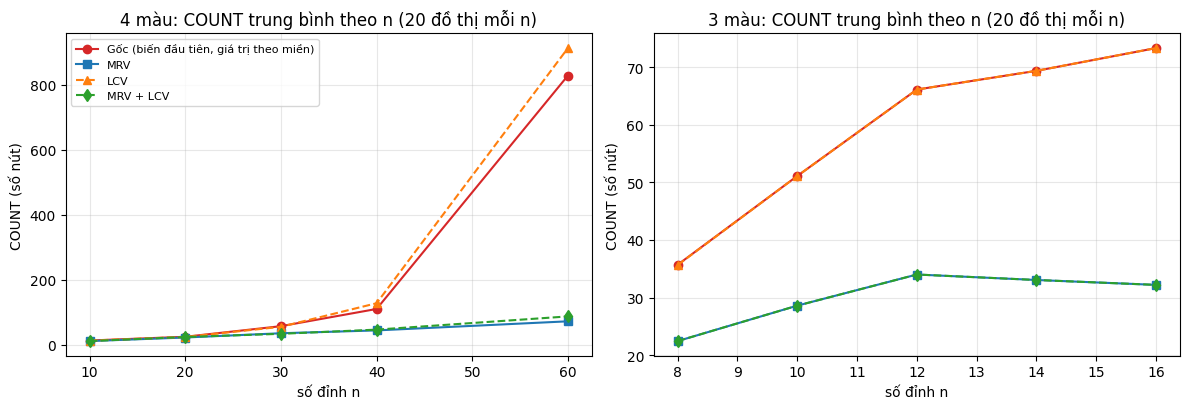

In [ ]:
# bảng ATTEMPTS trung bình
for k in (4, 3):
    print(f"\n=== {k} màu: ATTEMPTS trung bình (số lần thử gán) ===")
    piv = df[df.colors == k].pivot_table(index='n', columns='variant', values='att_mean')[list(variants)]
    print(piv.round(1).to_string())

# bảng thời gian trung bình (ms/lần)
for k in (4, 3):
    print(f"\n=== {k} màu: thời gian trung bình mỗi lần chạy (ms) ===")
    piv = df[df.colors == k].pivot_table(index='n', columns='variant', values='ms_mean')[list(variants)]
    print(piv.round(2).to_string())

# biểu đồ COUNT theo n
fig, axs = plt.subplots(1, 2, figsize=(12, 4.2))
styles = {'Gốc (biến đầu tiên, giá trị theo miền)': ('o-', 'tab:red'), 'MRV': ('s-', 'tab:blue'),
          'LCV': ('^--', 'tab:orange'), 'MRV + LCV': ('d--', 'tab:green')}
for ax, k in zip(axs, (4, 3)):
    for name in variants:
        d = df[(df.colors == k) & (df.variant == name)]
        ax.plot(d.n, d.count_mean, styles[name][0], color=styles[name][1], label=name)
    ax.set_title(f"{k} màu: COUNT trung bình theo n (20 đồ thị mỗi n)")
    ax.set_xlabel("số đỉnh n"); ax.set_ylabel("COUNT (số nút)"); ax.grid(alpha=.3)
axs[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig('figs/fig4_count_theo_n.png', dpi=150, bbox_inches='tight'); plt.show()

json.dump(RESULTS, open('results/csp_results.json', 'w'), ensure_ascii=False, indent=1)

## 3.6 Nhận xét tổng hợp Bài 3

Các nhận xét dưới đây dựa trên số liệu in ở ô trên (xem bảng trong báo cáo kèm theo).

1. **MRV giảm số nút (xét trung bình)**, và càng rõ khi đồ thị lớn hơn hoặc khi bài toán vô nghiệm (3 màu), vì MRV phát hiện sớm các biến "bí" và cắt cả nhánh con sớm hơn.
2. **LCV** giảm mạnh `ATTEMPTS` (số lần thử gán, xem bảng ATTEMPTS), nhưng cần đọc cẩn thận: một phần của mức giảm này là do `order_domain_lcv` chỉ trả về các giá trị còn hợp lệ nên không còn những lần thử bị `consistent()` loại, chứ không phải cây tìm kiếm nhỏ đi. Thật vậy LCV **không giảm `COUNT`**: ở 4 màu COUNT của LCV xấp xỉ bản gốc (n = 60 thậm chí 913 so với 829), ở 3 màu vô nghiệm COUNT hoàn toàn bằng bản gốc. Kết hợp MRV + LCV không tốt hơn MRV một mình về `COUNT` (n = 60: 87 so với 72), vì đồ thị phẳng 4 màu vốn rất "lỏng" nên phần lớn lợi ích đã đến từ MRV.
3. **Giảm số nút ≠ giảm thời gian.** MRV/LCV tính lại tập giá trị hợp lệ ở mỗi nút nên mỗi nút đắt hơn: với n nhỏ và với bài 3 màu (mọi n đã khảo sát), MRV tốn thời gian hơn bản gốc dù ít nút hơn. MRV chỉ thắng về thời gian khi bản gốc quay lui nhiều (4 màu, n ≥ 40; ở n = 60 bản gốc chậm hơn MRV nhiều lần, xem bảng thời gian). Thời gian mỗi lần chạy xấp xỉ tỉ lệ với `ATTEMPTS` × chi phí `consistent()` ($O(|E|)$), nên LCV cũng rút ngắn thời gian ở n = 60 (nhanh hơn bản gốc, nhưng chậm hơn MRV) dù không giảm `COUNT`.
4. Mọi nghiệm tìm được đều được kiểm tra bằng `is_solution`; mọi lần "vô nghiệm" là do **duyệt hết cây**, không phải do chạm giới hạn (cột `limit` bằng 0).
5. Hạn chế: (a) 20 đồ thị mỗi n là mẫu nhỏ; (b) thời gian đo bằng một lần chạy cho mỗi đồ thị nên nhiễu; (c) `consistent()` quét toàn bộ danh sách ràng buộc ($O(|E|)$ mỗi nút), nếu duyệt theo láng giềng sẽ nhanh hơn và làm thay đổi tỉ lệ thời gian giữa các biến thể.